# 02 V3 · 논문용 검증 보강판 — V2 결과를 보존한 사후 분석

**현재 수치는 논문에 사용할 수 있습니다. 다만 두 변조 유형을 모두 잘 탐지했다고 주장할 수 없습니다.**
이 노트북은 성공적으로 완료한 V2의 Drive 저장 모델·점수를 이어받습니다. V2를 다시 학습할 필요가 없습니다.
기존 모델·임계값을 고정하여 진단하고, 별도의 `random_forest_v3_audit` 폴더에 결과를 저장합니다.
V2 파일이 없으면 먼저 V2가 완료된 Drive 계정·경로를 확인하세요. 입력 데이터가 변경되면 중단합니다.

## 제출받은 실행 결과에 대한 판단
| 지표 | 실제 값 | 해석 |
|---|---:|---|
| Precision | 53.1655% | 의심 판정 1,311건 중 697건만 합성 변조 |
| Recall | 46.4667% | 변조 1,500건 중 803건 누락 |
| F1 | 0.495909 | 연구용 기준 모델로 보고 가능, 고성능 주장 부족 |
| AP | 0.406844 | 양성 비율 0.06156%인 실험의 점수 순위 평가 |
| ROC-AUC | 0.986716 | 높지만 판정 성능·이름 변조 탐지 실패를 대체하지 못함 |
| 정상 FPR | 0.025213% | 정상 10,000건당 약 2.52건, 총 614건 오탐 |
| 등급+무기 변조 Recall | 69.7% | 697/1,000 |
| 캐릭터명 변조 Recall | 0% | 0/500. 반드시 실패 결과로 함께 보고 |
| F1 사용자 95% CI | 0.473158~0.520758 | V2 고정 모델의 표본 불확실성 |

정확도 99.9418%는 정상 비중이 매우 큰 영향을 줍니다. 모두 정상이라고 해도 약 99.9384%입니다.
학습 합성 양성 비율은 약 1.50%, 테스트는 약 0.0616%로 다릅니다. 정밀도와 AP는 양성 비율에 영향을 받으므로 이 실험 설계를 명시해야 합니다.
숫자가 낮다는 이유로 연구 결과를 버릴 필요는 없습니다. 연구 질문·기준선·한계를 명확히 보고해야 합니다.

## 실행
- CPU 런타임, 위에서 아래로 **7개 코드 셀**을 실행합니다. Drive 연결을 허용하세요.
- 첫 셀 `BASE`는 기존 경로입니다. 재학습 없이 저장된 V2 모델을 불러옵니다.
- `RUN_SEED_STABILITY=True`가 기본입니다. 학습 시드 43·44를 추가하여 **검증 데이터에서만** 비교합니다.
- 추가 학습 모델의 테스트 점수를 확인하거나 가장 좋은 시드를 선택하지 않습니다.
- 원본·점수는 묶음 처리하며 대형 행렬 전체를 생성하지 않습니다. 반복 검증에는 시간이 추가로 소요됩니다.
- sklearn 버전이 V2 저장 당시와 다르면 중단합니다. 오류에 표시된 버전을 설치하고 런타임 재시작 후 실행하세요.

## 중요한 연구 절차
테스트 결과를 확인한 뒤 추가한 분석이므로 **사후 진단(post-hoc)**으로 명시합니다.
V3는 성능을 높이는 튜닝 버전이 아닙니다. 테스트에 맞춰 모델을 수정하면 같은 데이터를 독립 최종 평가로 재사용할 수 없습니다.
새로운 특징/모델을 개발하려면 train 내부의 사용자 분리로 개발하고, 별도 미사용 holdout을 사전 고정해야 합니다.


## 1. 환경 설정

In [1]:
# CPU 일반 런타임에서 실행. 새 런타임에서 위에서 아래로 실행하세요.
import os
for key in ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'NUMEXPR_NUM_THREADS']:
    os.environ[key] = '2'
import importlib.util, subprocess, sys
packages = {'pyarrow':'pyarrow', 'sklearn':'scikit-learn', 'scipy':'scipy',
            'pandas':'pandas', 'numpy':'numpy', 'matplotlib':'matplotlib', 'joblib':'joblib'}
missing = [v for k,v in packages.items() if importlib.util.find_spec(k) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])
from pathlib import Path
if not Path('/content/drive/MyDrive').exists():
    from google.colab import drive
    drive.mount('/content/drive')
import json, gc, time, hashlib, shutil, platform
import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
BASE = Path('/content/drive/MyDrive/캡스톤 2/capstonedata2')
PROCESSED = BASE / 'genshin_processed'
DATA = BASE / 'rf_model_data'
OUT = BASE / 'capstone_final_v2'
OUT.mkdir(parents=True, exist_ok=True)
BATCH = 65536
SEED = 42
BANNER = {'100':'beginner', '200':'standard', '301':'character_event',
          '302':'weapon_event', '400':'character_event'}
KEY = ['user_id', 'gacha_id']
RAW = KEY + ['name_zh','name_ko','gacha_type','item_type','rank_type','gacha_time']

def save_json(obj, path):
    tmp = Path(str(path)+'.tmp')
    tmp.write_text(json.dumps(obj, ensure_ascii=False, indent=2, default=str), encoding='utf-8')
    os.replace(tmp, path)

def fingerprint(path):
    p = Path(path)
    return {'path':str(p), 'bytes':p.stat().st_size, 'mtime_ns':p.stat().st_mtime_ns}

def canonical(df):
    df = df.copy()
    for c in KEY:
        assert df[c].notna().all(), f'{c} 결측'
        df[c] = df[c].astype(str).str.strip()
        assert df[c].ne('').all(), f'{c} 빈 값'
    df['gacha_type'] = pd.to_numeric(df['gacha_type'], errors='raise').astype('int16').astype(str)
    for c in ['item_type','rank_type']:
        df[c] = pd.to_numeric(df[c], errors='raise').astype('int8')
    df['gacha_time'] = pd.to_datetime(df['gacha_time'], errors='raise')
    for c in ['name_zh','name_ko']:
        df[c] = df[c].astype('string')
    assert df[RAW].notna().all().all(), '원본 필수 열 결측'
    assert df['gacha_type'].isin(BANNER).all(), '알 수 없는 배너'
    assert df['item_type'].isin([0,1]).all() and df['rank_type'].isin([3,4,5]).all()
    return df

print('준비 완료 | 묶음 크기:', BATCH, '| 결과 폴더:', OUT)


Mounted at /content/drive
준비 완료 | 묶음 크기: 65536 | 결과 폴더: /content/drive/MyDrive/캡스톤 2/capstonedata2/capstone_final_v2


## 2. V2 모델·입력 파일 일치 확인

In [2]:
import joblib, sklearn, scipy
from sklearn.base import clone
from sklearn.metrics import precision_recall_curve,average_precision_score,roc_auc_score,auc,confusion_matrix
from scipy.stats import binomtest
from threadpoolctl import threadpool_limits
threadpool_limits(limits=2)
V2=OUT/'random_forest_v2'
RUN=OUT/'random_forest_v3_audit'
RUN.mkdir(exist_ok=True)
N_BUCKETS=16;PREDICT_BATCH=16384;BOOTSTRAPS=1000
RUN_SEED_STABILITY=True  # 시간 여유가 없으면 False. 생략 여부가 보고서에 기록됩니다.
STABILITY_SEEDS=[43,44]  # 원래 seed=42 결과와 함께 3회. 가장 좋은 seed를 고르지 않습니다.
CAT=['gacha_type','name_ko','banner_group'];NUM=['item_type','rank_type','time_diff_seconds'];FEATURES=CAT+NUM
manifest=json.loads((V2/'experiment_manifest.json').read_text())
lock=json.loads((V2/'decision_threshold.json').read_text())
spec=json.loads((V2/'feature_spec.json').read_text())
assert sklearn.__version__==manifest['versions']['sklearn'], (
 f"모델 저장 당시 sklearn={manifest['versions']['sklearn']}, 현재={sklearn.__version__}. "
 '동일 버전을 설치하고 런타임을 다시 시작하세요. 다른 버전에서 저장 모델을 로드하지 않습니다.')
assert hashlib.sha256((V2/'random_forest_pipeline.joblib').read_bytes()).hexdigest()==lock['model_sha256']
model=joblib.load(V2/'random_forest_pipeline.joblib');model.set_params(rf__n_jobs=2)
THRESHOLD=float(lock['threshold']);NAME_MAP=spec['name_map']
assert spec['features']==FEATURES and spec['time_diff_group']==['user_id','banner_group']
for name,old in manifest['sources'].items():
    assert fingerprint(DATA/name)==old, f'기존 실험 입력이 바뀌었습니다: {name}. V2 결과와 섞을 수 없습니다.'
split=pd.read_csv(DATA/'rf_split_users.csv',dtype={'user_id':str})
assert not split['user_id'].duplicated().any()
sets={s:set(split.loc[split['split'].eq(s),'user_id']) for s in ['train','val','test']}
assert sets['train'].isdisjoint(sets['val']|sets['test']) and sets['val'].isdisjoint(sets['test'])
val_scores=pd.read_parquet(V2/'validation_scores.parquet')
test_scores=pd.read_parquet(V2/'test_scores.parquet')
assert len(test_scores)==pq.ParquetFile(DATA/'rf_test_raw.parquet').metadata.num_rows
assert len(val_scores)==pq.ParquetFile(DATA/'rf_validation_raw.parquet').metadata.num_rows
for name,s in [('validation',val_scores),('test',test_scores)]:
    assert s['score'].between(0,1).all() and s['label'].isin([0,1]).all()
    assert np.array_equal(s['label'].to_numpy(),s['type_code'].gt(0).astype('int8').to_numpy())
print('V2 모델과 임계값 동결:',THRESHOLD,'| 결과 저장:',RUN)


V2 모델과 임계값 동결: 0.9407435655593872 | 결과 저장: /content/drive/MyDrive/캡스톤 2/capstonedata2/capstone_final_v2/random_forest_v3_audit


## 3. 공통 처리 함수

In [3]:
def prepare_history(raw, replacements):
    """원본 식별자로 교체하고 모든 split에 동일한 과거 시간차를 계산합니다."""
    d=canonical(raw[RAW]).reset_index(drop=True)
    assert not d.duplicated(KEY).any(), '중복 식별자'
    d['name_ko']=d['name_zh'].map(NAME_MAP).fillna(d['name_ko']).astype('string')
    d['label']=np.int8(0);d['tamper_type']='normal'
    if len(replacements):
        r=canonical(replacements[RAW]).reset_index(drop=True)
        r['tamper_type']=replacements['tamper_type'].to_numpy()
        assert not r.duplicated(KEY).any()
        keys=pd.MultiIndex.from_frame(d[KEY]); rkeys=pd.MultiIndex.from_frame(r[KEY])
        pos=keys.get_indexer(rkeys); assert (pos>=0).all(), '원본에 없는 변조 키'
        for c in ['gacha_type','gacha_time','item_type']:
            assert np.array_equal(d.iloc[pos][c].to_numpy(),r[c].to_numpy()), f'의도하지 않은 {c} 변경'
        r['name_ko']=r['name_zh'].map(NAME_MAP).fillna(r['name_ko']).astype('string')
        assert (d.iloc[pos]['name_ko'].to_numpy()!=r['name_ko'].to_numpy()).all(), '실제 이름 변경 없음'
        a=r['tamper_type'].eq('item_and_rank_change').to_numpy()
        b=r['tamper_type'].eq('character_name_change').to_numpy()
        assert (a|b).all()
        assert (d.iloc[pos[a]]['rank_type'].eq(3)&d.iloc[pos[a]]['item_type'].eq(1)).all()
        assert r.loc[a,'rank_type'].eq(5).all()
        assert (d.iloc[pos[b]]['rank_type'].eq(4)&d.iloc[pos[b]]['item_type'].eq(0)).all()
        assert r.loc[b,'rank_type'].eq(4).all()
        for c in ['name_zh','name_ko','rank_type','tamper_type']:
            d.loc[pos,c]=r[c].to_numpy()
        d.loc[pos,'label']=np.int8(1)
    d['banner_group']=d['gacha_type'].map(BANNER)
    # ID를 float로 바꾸지 않아 큰 정수의 정밀도를 보존합니다.
    assert d['gacha_id'].str.fullmatch(r'\d+').all(), '숫자가 아닌 gacha_id'
    d['_order']=pd.to_numeric(d['gacha_id'],errors='raise').astype('uint64')
    d=d.sort_values(['user_id','banner_group','gacha_time','_order'],kind='stable').reset_index(drop=True)
    d['time_diff_seconds']=d.groupby(['user_id','banner_group'],sort=False)['gacha_time'].diff().dt.total_seconds().astype('float32')
    assert d['time_diff_seconds'].dropna().ge(0).all()
    for c in CAT:d[c]=d[c].astype(str)
    return d.drop(columns='_order')

def read_replacements(path, kind=None):
    cols=RAW+([] if kind else ['tamper_type'])
    r=pd.read_parquet(path,columns=cols)
    if kind:r['tamper_type']=kind
    r=canonical(r)
    return r

# 같은 사용자의 전체 이력을 한 버킷으로 모읍니다. 청크 경계에서 시간차가 끊기지 않습니다.
def stage_raw(path, expected_users, tag):
    root=Path('/content/capstone_v2_work')/tag
    root.mkdir(parents=True,exist_ok=True)
    marker=root/'complete.json'; sig={'source':fingerprint(path),'buckets':N_BUCKETS,'version':2,
        'users_sha256':hashlib.sha256('\n'.join(sorted(expected_users)).encode()).hexdigest()}
    if marker.exists() and json.loads(marker.read_text())==sig:
        return root
    marker.unlink(missing_ok=True)
    for p in root.glob('bucket-*.parquet'):p.unlink()
    writers={};seen=set();total=0
    try:
        for b in pq.ParquetFile(path).iter_batches(batch_size=BATCH,columns=RAW):
            d=canonical(b.to_pandas());seen.update(d['user_id']);total+=len(d)
            assert set(d['user_id']).issubset(expected_users), '사용자 분할 누출'
            bucket=(pd.util.hash_pandas_object(d['user_id'],index=False).to_numpy()%N_BUCKETS).astype(int)
            for k in np.unique(bucket):
                t=pa.Table.from_pandas(d.loc[bucket==k,RAW],preserve_index=False)
                if k not in writers: writers[k]=pq.ParquetWriter(root/f'bucket-{k:02d}.parquet',t.schema,compression='zstd')
                writers[k].write_table(t)
        assert seen==expected_users, '예상 사용자 누락'
        assert total==pq.ParquetFile(path).metadata.num_rows
    finally:
        for w in writers.values():w.close()
    save_json(sig,marker)
    return root

def make_test_replacements(root):
    # 독립 난수의 작은 우선순위 표본만 유지: 전체 후보를 RAM에 적재하지 않습니다.
    rng=np.random.default_rng(TEST_SEED);samples=[pd.DataFrame(),pd.DataFrame()]
    for path in sorted(root.glob('bucket-*.parquet')):
        for batch in pq.ParquetFile(path).iter_batches(batch_size=BATCH,columns=RAW):
            d=canonical(batch.to_pandas())
            for j,(rank,item,n) in enumerate([(3,1,N_RANK),(4,0,N_CHARACTER)]):
                cand=d.loc[d['rank_type'].eq(rank)&d['item_type'].eq(item)].copy()
                cand['_random']=rng.random(len(cand))
                samples[j]=pd.concat([samples[j],cand.nsmallest(n,'_random')],ignore_index=True).nsmallest(n,'_random')
    replacements=[]
    for j,(s,n,pool,kind) in enumerate(zip(samples,[N_RANK,N_CHARACTER],[weapon_pool,char_pool],['item_and_rank_change','character_name_change'])):
        assert len(s)==n, '합성 변조 후보 부족'
        s=s.drop(columns='_random').reset_index(drop=True)
        s['name_ko']=s['name_zh'].map(NAME_MAP).fillna(s['name_ko'])
        for i,old in enumerate(s['name_ko'].to_numpy()):
            options=pool if j==0 else pool.loc[pool['name_ko'].ne(old)]
            choice=options.iloc[rng.integers(len(options))]
            s.loc[i,['name_zh','name_ko']]=choice[['name_zh','name_ko']].to_numpy()
        if j==0:s['rank_type']=np.int8(5)
        s['tamper_type']=kind;replacements.append(s)
    result=pd.concat(replacements,ignore_index=True)
    assert not result.duplicated(KEY).any()
    return result

def score_split(root, replacements, expected_users, prefix):
    user_list=sorted(expected_users);user_map={u:i for i,u in enumerate(user_list)}
    blocks=[];matched=0;start=time.perf_counter();predict_seconds=0.
    for path in sorted(root.glob('bucket-*.parquet')):
        raw=pd.read_parquet(path,columns=RAW)
        rep=replacements.loc[replacements['user_id'].isin(set(raw['user_id'].astype(str)))]
        d=prepare_history(raw,rep);matched+=len(rep)
        score=np.empty(len(d),dtype='float32')
        for i in range(0,len(d),PREDICT_BATCH):
            tick=time.perf_counter()
            score[i:i+PREDICT_BATCH]=model.predict_proba(d.iloc[i:i+PREDICT_BATCH][FEATURES])[:,1]
            predict_seconds+=time.perf_counter()-tick
        block=pd.DataFrame({'user_code':d['user_id'].map(user_map).astype('int32'),
            'label':d['label'].astype('int8'),'type_code':d['tamper_type'].map({'normal':0,'item_and_rank_change':1,'character_name_change':2}).astype('int8'),
            'score':score})
        blocks.append(block)
        del raw,d,score;gc.collect()
    assert matched==len(replacements), '일부 변조 행 미반영'
    scores=pd.concat(blocks,ignore_index=True);del blocks
    assert int(scores['label'].sum())==len(replacements)
    scores.to_parquet(RUN/f'{prefix}_scores.parquet',index=False)
    pd.DataFrame({'user_code':range(len(user_list)),'user_id':user_list}).to_csv(RUN/f'{prefix}_user_codes.csv',index=False)
    timing={'total_seconds':time.perf_counter()-start,'predict_seconds':predict_seconds,'rows':len(scores),
            'prediction_rows_per_second':len(scores)/max(predict_seconds,1e-9)}
    save_json(timing,RUN/f'{prefix}_timing.json')
    return scores,timing


## 4. 규칙 기준선·변조 전후 대응 검증

In [4]:
def predict_small(frame, estimator=None):
    estimator=model if estimator is None else estimator
    return np.concatenate([estimator.predict_proba(frame.iloc[i:i+PREDICT_BATCH][FEATURES])[:,1].astype(np.float32).astype(np.float32)
                           for i in range(0,len(frame),PREDICT_BATCH)]) if len(frame) else np.array([])

def rule_prediction(frame):
    # 제한된 기준선: 캐릭터 이벤트 배너의 5성 무기 조합만 의심 처리.
    # 전체 게임 규칙을 구현한 검증기가 아닙니다. RF와 결합하지 않습니다.
    return (frame['gacha_type'].isin(['301','400']) & frame['rank_type'].eq(5) & frame['item_type'].eq(1)).to_numpy()

def audit_split(name,raw_name,replacements,scores,expected_users):
    root=stage_raw(DATA/raw_name,expected_users,name)
    user_list=sorted(expected_users);user_map={u:i for i,u in enumerate(user_list)}
    saved_codes=pd.read_csv(V2/f'{name}_user_codes.csv',dtype={'user_id':str})
    assert saved_codes['user_id'].tolist()==user_list
    assert saved_codes['user_code'].tolist()==list(range(len(user_list)))
    rows=[];pair_parts=[];offset=0;rf_cm=np.zeros((len(user_list),4),dtype=np.int64);rule_cm=rf_cm.copy()
    type_counts=np.zeros((len(user_list),3,2),dtype=np.int64)
    for path in sorted(root.glob('bucket-*.parquet')):
        raw=pd.read_parquet(path,columns=RAW)
        r=replacements.loc[replacements['user_id'].isin(set(raw['user_id'].astype(str)))]
        d=prepare_history(raw,r);saved=scores.iloc[offset:offset+len(d)];offset+=len(d)
        uc=d['user_id'].map(user_map).to_numpy();tc=d['tamper_type'].map({'normal':0,'item_and_rank_change':1,'character_name_change':2}).to_numpy()
        y=d['label'].to_numpy();pred=saved['score'].to_numpy()>=THRESHOLD;rule=rule_prediction(d)
        assert np.array_equal(saved['user_code'].to_numpy(),uc)
        assert np.array_equal(saved['type_code'].to_numpy(),tc) and np.array_equal(saved['label'].to_numpy(),y)
        # 일부 재예측으로 저장 점수와 모델의 대응도 확인합니다.
        ix=np.unique(np.r_[np.arange(min(8,len(d))),np.flatnonzero(y==1)])
        assert np.allclose(predict_small(d.iloc[ix]),saved.iloc[ix]['score'].to_numpy(),atol=1e-6)
        np.add.at(rf_cm,(uc,y.astype(int)*2+pred.astype(int)),1)
        np.add.at(rule_cm,(uc,y.astype(int)*2+rule.astype(int)),1)
        np.add.at(type_counts,(uc,tc,np.zeros(len(d),dtype=int)),1)
        np.add.at(type_counts,(uc,tc,np.ones(len(d),dtype=int)),pred.astype(int))
        d['_pred']=pred;d['_rule']=rule
        for (banner,rank,item),g in d.groupby(['banner_group','rank_type','item_type']):
            for method,col in [('RF','_pred'),('rule','_rule')]:
                z=confusion_matrix(g['label'],g[col],labels=[0,1]).ravel()
                rows.append([name,banner,int(rank),int(item),method,*z])
        if len(r):
            clean=prepare_history(raw,pd.DataFrame(columns=RAW+['tamper_type']))
            assert np.array_equal(d[KEY].to_numpy(),clean[KEY].to_numpy())
            mask=y==1;original_score=predict_small(clean.loc[mask])
            pair=d.loc[mask,KEY+['tamper_type','banner_group','rank_type','name_ko']].copy()
            pair['user_code']=uc[mask];pair['original_score']=original_score
            pair['tampered_score']=saved.loc[saved['label'].eq(1),'score'].to_numpy()
            pair['score_delta']=pair['tampered_score']-pair['original_score']
            pair['original_flag']=original_score>=THRESHOLD;pair['tampered_flag']=pred[mask]
            pair_parts.append(pair)
        del raw,d;gc.collect()
    assert offset==len(scores)
    pairs=pd.concat(pair_parts,ignore_index=True);assert len(pairs)==len(replacements)
    pairs.to_csv(RUN/f'{name}_paired_before_after.csv',index=False,encoding='utf-8-sig')
    grouped=pd.DataFrame(rows,columns=['split','banner','rank','item','method','tn','fp','fn','tp']).groupby(['split','banner','rank','item','method'],as_index=False)[['tn','fp','fn','tp']].sum()
    grouped.to_csv(RUN/f'{name}_subgroup_confusion.csv',index=False,encoding='utf-8-sig')
    np.savez_compressed(RUN/f'{name}_user_counts.npz',rf=rf_cm,rule=rule_cm,types=type_counts)
    return root,pairs,rf_cm,rule_cm,type_counts

val_rep=read_replacements(DATA/'rf_validation_tampered.parquet')
test_rep=read_replacements(V2/'test_synthetic_replacements.parquet')
val_root,val_pairs,val_cm,val_rule_cm,val_types=audit_split('validation','rf_validation_raw.parquet',val_rep,val_scores,sets['val'])
test_root,test_pairs,test_cm,test_rule_cm,test_types=audit_split('test','rf_test_raw.parquet',test_rep,test_scores,sets['test'])
print('저장 점수·사용자 분리·변조 전후 대응 검사 통과')


저장 점수·사용자 분리·변조 전후 대응 검사 통과


## 5. 추가 성능표·사용자 단위 신뢰구간

In [5]:
def counts_metrics(cm):
    tn,fp,fn,tp=np.asarray(cm,dtype=float)
    def div(a,b):return float(a/b) if b else 0.
    return dict(accuracy=div(tp+tn,tn+fp+fn+tp),precision=div(tp,tp+fp),recall=div(tp,tp+fn),
        f1=div(2*tp,2*tp+fp+fn),FPR=div(fp,tn+fp),FP_per_10000_normal=10000*div(fp,tn+fp),
        MCC=div(tp*tn-fp*fn,np.sqrt((tp+fp)*(tp+fn)*(tn+fp)*(tn+fn))))
comparison=[];type_rows=[];pair_rows=[];ci_rows=[]
for name,s,cm,rcm,types,pairs in [('validation',val_scores,val_cm,val_rule_cm,val_types,val_pairs),('test',test_scores,test_cm,test_rule_cm,test_types,test_pairs)]:
    for label,mat in [('RF',cm),('limited_rule',rcm)]:
        comparison.append({'split':name,'method':label,**counts_metrics(mat.sum(axis=0))})
    y=s['label'].to_numpy();p=s['score'].to_numpy();pr,re,_=precision_recall_curve(y,p)
    ref=counts_metrics(cm.sum(axis=0));ref.update(AP=average_precision_score(y,p),PR_AUC_trapezoid=auc(re,pr),ROC_AUC=roc_auc_score(y,p),prevalence=float(y.mean()))
    save_json(ref,RUN/f'{name}_verified_metrics.json')
    for code,label in enumerate(['normal','item_and_rank_change','character_name_change']):
        total,flag=types[:,code,:].sum(axis=0)
        # 이 구간은 행 독립을 가정한 참고치. 사용자 군집 CI와 구별합니다.
        exact=binomtest(int(flag),int(total)).proportion_ci(confidence_level=.95,method='exact')
        type_rows.append({'split':name,'type':label,'rows':int(total),'flagged':int(flag),'rate':flag/total,
                         'row_iid_exact_low_reference':exact.low,'row_iid_exact_high_reference':exact.high})
    for label,g in pairs.groupby('tamper_type'):
        pair_rows.append({'split':name,'type':label,'n':len(g),'mean_score_delta':g['score_delta'].mean(),
            'median_score_delta':g['score_delta'].median(),'original_flagged':int(g['original_flag'].sum()),
            'tampered_flagged':int(g['tampered_flag'].sum()),'newly_flagged':int((~g['original_flag']&g['tampered_flag']).sum()),
            'lost_flags':int((g['original_flag']&~g['tampered_flag']).sum())})
# 사용자 단위의 짝지은 부트스트랩: RF-규칙 F1 차이와 유형별 비율.
rng=np.random.default_rng(SEED);samples=[]
for _ in range(BOOTSTRAPS):
    ix=rng.integers(len(test_cm),size=len(test_cm))
    rf=counts_metrics(test_cm[ix].sum(axis=0));rule=counts_metrics(test_rule_cm[ix].sum(axis=0))
    row={'F1_RF_minus_rule':rf['f1']-rule['f1']}
    for code,label in enumerate(['normal_FPR','rank_recall','character_recall']):
        n,k=test_types[ix,code,:].sum(axis=0);row[label]=k/n if n else np.nan
    samples.append(row)
for k in samples[0]:
    values=np.array([r[k] for r in samples]);lo,hi=np.nanpercentile(values,[2.5,97.5])
    ci_rows.append({'metric':k,'low_95':lo,'high_95':hi,'unit':'user','B':BOOTSTRAPS,
                    'degenerate_observed_sample':bool(np.nanmin(values)==np.nanmax(values))})
# 양성 비율을 바꿨을 때 정밀도: TPR/FPR 불변을 가정한 계산이며 실측 배포 성능이 아닙니다.
m=counts_metrics(test_cm.sum(axis=0));sensitivity=[]
for prevalence in [.0001,.0005,.001,.005,.01]:
    den=m['recall']*prevalence+m['FPR']*(1-prevalence)
    sensitivity.append({'assumed_prevalence':prevalence,'expected_precision_if_TPR_FPR_fixed':m['recall']*prevalence/den if den else np.nan})
for file,rows in [('baseline_comparison',comparison),('type_rates_with_reference_intervals',type_rows),
                  ('paired_change_summary',pair_rows),('test_cluster_bootstrap',ci_rows),('prevalence_sensitivity',sensitivity)]:
    pd.DataFrame(rows).to_csv(RUN/f'{file}.csv',index=False,encoding='utf-8-sig')
    display(pd.DataFrame(rows).round(6))
print('0/500의 군집 부트스트랩 [0,0]은 실제 위험·탐지 확률이 0이라는 증거가 아닙니다.')


,split,method,accuracy,precision,recall,f1,FPR,FP_per_10000_normal,MCC
0,validation,RF,0.999447,0.567347,0.463333,0.510092,0.000220,2.198761,0.512437
1,validation,limited_rule,0.999659,1.000000,0.451333,0.621957,0.000000,0.000000,0.671699
2,test,RF,0.999418,0.531655,0.464667,0.495909,0.000252,2.521269,0.496745
3,test,limited_rule,0.999655,1.000000,0.440000,0.611111,0.000000,0.000000,0.663211


,split,type,rows,flagged,rate,row_iid_exact_low_reference,row_iid_exact_high_reference
0,validation,normal,2410448,530,0.000220,0.000202,0.000239
1,validation,item_and_rank_change,1000,695,0.695000,0.665420,0.723427
2,validation,character_name_change,500,0,0.000000,0.000000,0.007351
3,test,normal,2435282,614,0.000252,0.000233,0.000273
4,test,item_and_rank_change,1000,697,0.697000,0.667467,0.725368
5,test,character_name_change,500,0,0.000000,0.000000,0.007351


,split,type,n,mean_score_delta,median_score_delta,original_flagged,tampered_flagged,newly_flagged,lost_flags
0,validation,character_name_change,500,0.024180,0.015793,0,0,0,0
1,validation,item_and_rank_change,1000,0.914497,0.926426,0,695,695,0
2,test,character_name_change,500,0.023817,0.016027,0,0,0,0
3,test,item_and_rank_change,1000,0.913220,0.927064,0,697,697,0


,metric,low_95,high_95,unit,B,degenerate_observed_sample
0,F1_RF_minus_rule,-0.132890,-0.096881,user,1000,False
1,normal_FPR,0.000230,0.000273,user,1000,False
2,rank_recall,0.668832,0.727836,user,1000,False
3,character_recall,0.000000,0.000000,user,1000,True


,assumed_prevalence,expected_precision_if_TPR_FPR_fixed
0,0.0001,0.155632
1,0.0005,0.479696
2,0.0010,0.648485
3,0.0050,0.902546
4,0.0100,0.949021


0/500의 군집 부트스트랩 [0,0]은 실제 위험·탐지 확률이 0이라는 증거가 아닙니다.


## 6. 학습 시드 안정성 — 검증 데이터만

In [6]:
stability=[]
if RUN_SEED_STABILITY:
    normal=canonical(pd.read_parquet(DATA/'rf_normal_candidates.parquet',columns=RAW))
    a=read_replacements(DATA/'rf_tampered_item_raw.parquet','item_and_rank_change')
    b=read_replacements(DATA/'rf_tampered_character_raw.parquet','character_name_change')
    train=prepare_history(normal,pd.concat([a,b],ignore_index=True))
    assert set(train['user_id']).issubset(sets['train'])
    frozen=model
    try:
        for seed in [42]+STABILITY_SEEDS:
            if seed==42:s=val_scores
            else:
                model=clone(frozen).set_params(rf__random_state=seed,rf__n_jobs=2)
                model.fit(train[FEATURES],train['label'])
                s,_=score_split(val_root,val_rep,sets['val'],f'validation_seed_{seed}')
            pred=s['score'].to_numpy()>=THRESHOLD
            cm=confusion_matrix(s['label'],pred,labels=[0,1]).ravel()
            row={'seed':seed,'split':'validation_only','threshold':THRESHOLD,**counts_metrics(cm),
                 'AP':average_precision_score(s['label'],s['score'])}
            for code,label in [(1,'rank_recall'),(2,'character_recall')]:
                mask=s['type_code'].eq(code).to_numpy();row[label]=float(pred[mask].mean())
            stability.append(row)
    finally:model=frozen
    pd.DataFrame(stability).to_csv(RUN/'validation_training_seed_stability.csv',index=False,encoding='utf-8-sig')
    display(pd.DataFrame(stability).round(6))
    del normal,train,a,b;gc.collect()
else:print('반복 학습 검증 생략: 보고서에 미실시로 표시합니다.')
# 추가 모델의 테스트 평가는 하지 않습니다. 가장 좋은 시드도 선택하지 않습니다.
assert model is not None


,seed,split,threshold,accuracy,precision,recall,f1,FPR,FP_per_10000_normal,MCC,AP,rank_recall,character_recall
0,42,validation_only,0.940744,0.999447,0.567347,0.463333,0.510092,0.000220,2.198761,0.512437,0.411888,0.695,0.0
1,43,validation_only,0.940744,0.999446,0.652985,0.233333,0.343811,0.000077,0.771641,0.390130,0.376571,0.350,0.0
2,44,validation_only,0.940744,0.999396,0.526316,0.293333,0.376712,0.000164,1.642848,0.392646,0.374931,0.440,0.0


## 7. 논문용 요약·그림 저장

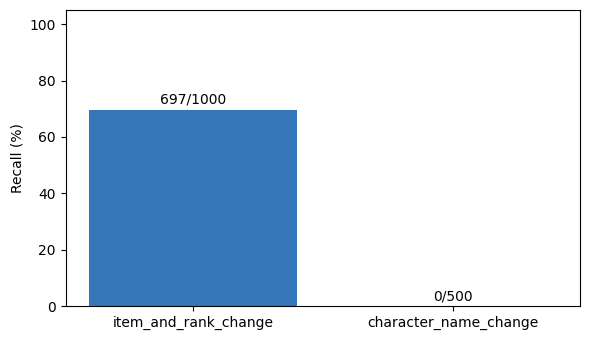

# V3 논문용 보완 검증
## 판정
수치는 연구 결과로 보고할 수 있으나, 고성능의 범용 변조 탐지/실서비스 적용을 입증하지 않는다.
본 V3는 테스트 결과 확인 후 설계한 사후 분석이다. V2 모델·특징·임계값을 변경하지 않았다.
V2의 최초 평가와 V3의 사후 진단을 논문에서 구분하여 서술해야 한다.

## 고정 V2 모델의 테스트 결과
Precision=0.531655, Recall=0.464667, F1=0.495909, AP=0.406844, ROC-AUC=0.986716.
정상 10,000건당 오탐=2.521. 합성 양성 비율=0.00061557.
전체 정확도보다 AP·Precision·Recall·유형별 성능을 우선 보고한다.

## 추가 결과 위치
- baseline_comparison.csv: 제한된 배너 규칙과 RF 비교. 모든 게임 규칙을 구현한 강한 기준선은 아님.
- paired_change_summary.csv: 변조 전부터 의심되던 기록인지, 실제 변조로 점수가 상승했는지 확인.
- type_rates_with_reference_intervals.csv: 유형별 탐지율 및 행 독립 가정의 참고 구간.
- test_cluster_bootstrap.csv: 사용자 단위 유형별 구간과 RF-규칙 F1 차이 구간.
- validation_training_seed_stability.csv: 반복 학습 검증 실시. 검증 데이터만 사용하며 최적 시드를 선택하지 않음.
- prevalence_sensitivity.csv: 양성 비율에 따른 정밀도 민감도. TPR/FPR 불변 가정의 계산이며 배포 성능 아님.

## 아직 남은 제한
학습 사용자 116명, 단일 학습 표본, 합성 변조 두 종류만 사용했다.
이름 변경 탐지 0건을 성공으로 해석하거나 해당 유형을 사후 삭제하여 전체 F1을 올리지 않는다.
AP/ROC-AUC 자체의 사용자 단위 CI, 여러 사용자 분할의 재학습, 시간 외삽/실제 변조 라벨 검증은 수행하지 않았다.
모델을 개선하려면 tr

In [7]:
import matplotlib.pyplot as plt
fig,ax=plt.subplots(figsize=(6,3.5))
view=pd.DataFrame(type_rows).query("split=='test' and type!='normal'")
ax.bar(view['type'],view['rate']*100,color=['#3478ba','#be6773']);ax.set_ylim(0,105);ax.set_ylabel('Recall (%)')
for i,r in enumerate(view.itertuples()):ax.text(i,r.rate*100+2,f'{r.flagged}/{r.rows}',ha='center')
fig.tight_layout();fig.savefig(RUN/'test_type_recall.png',dpi=200);plt.show();plt.close(fig)
metrics=json.loads((RUN/'test_verified_metrics.json').read_text())
summary=f'''# V3 논문용 보완 검증
## 판정
수치는 연구 결과로 보고할 수 있으나, 고성능의 범용 변조 탐지/실서비스 적용을 입증하지 않는다.
본 V3는 테스트 결과 확인 후 설계한 사후 분석이다. V2 모델·특징·임계값을 변경하지 않았다.
V2의 최초 평가와 V3의 사후 진단을 논문에서 구분하여 서술해야 한다.

## 고정 V2 모델의 테스트 결과
Precision={metrics['precision']:.6f}, Recall={metrics['recall']:.6f}, F1={metrics['f1']:.6f}, AP={metrics['AP']:.6f}, ROC-AUC={metrics['ROC_AUC']:.6f}.
정상 10,000건당 오탐={metrics['FP_per_10000_normal']:.3f}. 합성 양성 비율={metrics['prevalence']:.8f}.
전체 정확도보다 AP·Precision·Recall·유형별 성능을 우선 보고한다.

## 추가 결과 위치
- baseline_comparison.csv: 제한된 배너 규칙과 RF 비교. 모든 게임 규칙을 구현한 강한 기준선은 아님.
- paired_change_summary.csv: 변조 전부터 의심되던 기록인지, 실제 변조로 점수가 상승했는지 확인.
- type_rates_with_reference_intervals.csv: 유형별 탐지율 및 행 독립 가정의 참고 구간.
- test_cluster_bootstrap.csv: 사용자 단위 유형별 구간과 RF-규칙 F1 차이 구간.
- validation_training_seed_stability.csv: 반복 학습 검증 {'실시' if RUN_SEED_STABILITY else '미실시'}. 검증 데이터만 사용하며 최적 시드를 선택하지 않음.
- prevalence_sensitivity.csv: 양성 비율에 따른 정밀도 민감도. TPR/FPR 불변 가정의 계산이며 배포 성능 아님.

## 아직 남은 제한
학습 사용자 116명, 단일 학습 표본, 합성 변조 두 종류만 사용했다.
이름 변경 탐지 0건을 성공으로 해석하거나 해당 유형을 사후 삭제하여 전체 F1을 올리지 않는다.
AP/ROC-AUC 자체의 사용자 단위 CI, 여러 사용자 분할의 재학습, 시간 외삽/실제 변조 라벨 검증은 수행하지 않았다.
모델을 개선하려면 train 내부 사용자 단위 개발 분할로 특징을 설계하고, 기존 test를 새로운 최종 미사용 자료라고 부르지 않는다.
전체 원본에서 아직 학습·검증에 쓰지 않은 train 사용자 집합을 사전에 잠근 추가 holdout 또는 별도 수집 자료로 최종 확인하는 방안을 검토한다.
이미 사용한 전체자료 기반 통계와 자료 노출 범위도 명시한다. 재학습·새 holdout은 본 V3에서 자동 실행하지 않는다.
학술지/교수의 채택 여부나 성능 통과선을 보장하지 않는다.

## 참고
- https://scikit-learn.org/stable/auto_examples/model_selection/plot_precision_recall.html
- https://scikit-learn.org/stable/common_pitfalls.html
'''
(RUN/'paper_audit_summary.md').write_text(summary,encoding='utf-8')
save_json({'analysis':'post-hoc audit; original V2 frozen','threshold':THRESHOLD,
 'original_model_sha256':lock['model_sha256'],'seed_stability_enabled':RUN_SEED_STABILITY,
 'additional_training_seeds':STABILITY_SEEDS if RUN_SEED_STABILITY else [],'bootstrap_repetitions':BOOTSTRAPS,
 'sklearn':sklearn.__version__},RUN/'audit_manifest.json')
assert hashlib.sha256((V2/'random_forest_pipeline.joblib').read_bytes()).hexdigest()==lock['model_sha256']
print(summary);print('V3 보완 검증 완료:',RUN)


## 검증의 한계와 다음 판단
- 규칙 기준선은 ‘캐릭터 이벤트 배너의 5성 무기’만 검사합니다. 전체 게임 규칙 검증기는 아닙니다.
- 변조 전후 점수를 비교해 원래부터 의심되던 행인지 확인합니다. 점수 상승이 곧 실제 공격 검출 증거는 아닙니다.
- 0/500의 사용자 부트스트랩 구간이 [0,0]이라도 모집단 탐지율 0을 확정하지 않습니다. 행 독립 가정의 참고 exact 구간을 별도로 제공합니다.
- 학습 시드 안정성은 고정된 116명 학습 표본에 대한 것입니다. 여러 사용자 분할·시간 외삽·실제 공격 라벨 검증은 추가로 필요합니다.
- V3 코드의 소규모 합성 자료 실행 검증과 실제 자료 평가를 구별하세요. 실제 V3 수치는 본인 Colab 실행 후 생성됩니다.

참고 문헌/공식 문서:
- [scikit-learn Precision–Recall](https://scikit-learn.org/stable/auto_examples/model_selection/plot_precision_recall.html)
- [scikit-learn Common pitfalls](https://scikit-learn.org/stable/common_pitfalls.html)
